### Orchestrator-worker

Orchestrator가 입력에 따라 작업을 나누고, 여러 Worker가 동적으로 병렬 실행한 결과를 모으는 방법을 배운다.

```
START → Orchestrator ─┬→ Worker
                      ├→ Worker ─→ 결과 종합 → END
                      └→ Worker
```

In [2]:
import operator
from typing import Annotated, TypedDict

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field

load_dotenv(override=True)

MODEL_NAME = "gemini-3.6-flash"
llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

### Orchestrator-worker와 Send API

고정 Fan-out은 그래프를 만들 때 작업의 종류와 수가 정해진다. Orchestrator-worker 패턴에서는 Orchestrator가 사용자 요청을 분석하여 실행 시점에 필요한 작업을 계획하고, `Send` API로 각 작업을 Worker에 전달한다.

`Send(노드이름, state)`는 지정한 Worker 노드를 새로운 입력 State로 실행한다. 라우팅 함수가 `Send` 객체의 리스트를 반환하면 리스트 길이만큼 동적 Fan-out이 일어난다. 작업 수를 미리 정하지 않아도 되므로 사용자 요청마다 서로 다른 수의 Worker를 실행할 수 있다.

```
START → create_plan(Orchestrator) ─┬→ analyze_task(Worker) ─┐
                                  ├→ analyze_task(Worker) ─┼→ make_report → END
                                  └→ analyze_task(Worker) ─┘
```

그래프의 실행 흐름은 다음과 같다.

- `create_plan`이 사용자 요청을 분석하여 작업 목록을 만든다.
- `assign_workers`가 작업마다 하나의 `Send` 객체를 만든다.
- 여러 `analyze_task`가 서로 독립된 입력을 받아 실행된다.
- 각 Worker의 결과가 `results`에 병합된다.
- 모든 Worker가 완료되면 `make_report`가 결과를 하나의 보고서로 종합한다.

### 전체 State와 Worker State

`ReportState`는 그래프 전체가 공유하는 상태다. 원본 요청, Orchestrator가 만든 작업 목록, Worker 결과, 최종 보고서를 저장한다. 반면 `WorkerState`는 Worker 한 개가 담당 작업을 처리하는 데 필요한 값만 가진다.

Worker들은 같은 `WorkerState` 스키마를 사용하지만, 각 `Send`가 전달하는 State 값은 서로 독립적이다. 예를 들어 `Send("analyze_task", {"task_id": 0, "title": "비용 분석", ...})`와 `Send("analyze_task", {"task_id": 1, "title": "위험 분석", ...})`는 같은 `analyze_task` 함수를 실행하지만 서로 다른 입력을 받는다. 따라서 Worker가 공유 State에서 자신의 작업을 다시 찾을 필요 없이 전달받은 State를 바로 사용하면 된다.

`task_id`는 Worker를 서로 다른 객체로 만드는 값이 아니다. 병렬 실행이 끝난 뒤 하나의 리스트에 합쳐진 결과가 어느 작업에서 나왔는지 식별하고, 원래 계획 순서로 정렬하기 위한 구분자다.

`results: Annotated[list, operator.add]`의 `operator.add`는 병렬 실행 결과를 합치는 **reducer**다. 여러 Worker가 각각 `results` 리스트를 반환하면 기존 값을 덮어쓰지 않고 하나의 리스트로 이어 붙인다. reducer가 없으면 여러 Worker가 같은 State 키를 동시에 갱신할 때 충돌이 발생할 수 있다.

In [3]:
class AnalysisTask(BaseModel):
    title: str = Field(description="분석 항목 제목")
    description: str = Field(description="분석할 내용")


class AnalysisPlan(BaseModel):
    tasks: list[AnalysisTask] = Field(description="보고서 작성에 필요한 분석 작업")


class ReportState(TypedDict):
    request: str
    tasks: list[AnalysisTask]
    results: Annotated[list, operator.add]
    final_report: str


class WorkerState(TypedDict):
    request: str
    task_id: int
    title: str
    description: str


def create_plan(state: ReportState):
    """사용자 요청을 분석하여 필요한 작업을 계획한다."""
    planner = llm.with_structured_output(AnalysisPlan)
    plan = planner.invoke(
        f"다음 요청에 대한 분석 보고서를 작성하려고 한다. "
        f"필요한 분석 작업을 3~5개로 나눠줘.\n\n요청: {state['request']}"
    )
    return {"tasks": plan.tasks}


def assign_workers(state: ReportState):
    """계획된 작업마다 Worker를 생성한다."""

    return [
        Send(
            "analyze_task",
            # WorkerState
            {
                "request": state["request"],
                "task_id": task_id,
                "title": task.title,
                "description": task.description,
            },
        )
        for task_id, task in enumerate(state["tasks"])
    ]


def analyze_task(state: WorkerState):
    result = llm.invoke(
        f"전체 요청을 고려하여 담당 항목을 구체적으로 분석해줘.\n\n"
        f"전체 요청: {state['request']}\n"
        f"담당 항목: {state['title']}\n"
        f"분석 내용: {state['description']}"
    )
    print(f"[analyze_task] '{state['title']}' 완료")

    # ReportState
    return {
        "results": [{
            "task_id": state["task_id"],
            "title": state["title"],
            "content": result.text,
        }]
    }


def make_report(state: ReportState):
    sorted_results = sorted(state["results"], key=lambda item: item["task_id"])
    all_results = "\n\n".join(
        f"### {item['title']}\n{item['content']}" for item in sorted_results
    )
    result = llm.invoke(
        f"다음 요청과 분석 결과를 바탕으로 하나의 보고서를 작성해줘.\n\n"
        f"요청: {state['request']}\n\n{all_results}"
    )
    return {"final_report": result.text}

### Orchestrator, 라우팅 함수, Worker

`create_plan`은 Orchestrator 역할을 한다. `with_structured_output(AnalysisPlan)`을 사용하므로 LLM의 응답을 문자열이 아니라 `AnalysisTask` 목록으로 받을 수 있다. 이 목록의 길이가 실행할 Worker 수를 결정한다.

`assign_workers`는 일반 노드가 아니라 **라우팅 함수**다. 각 작업을 `Send("analyze_task", worker_state)`로 바꾸어 반환한다. 두 번째 인자의 딕셔너리는 해당 Worker만 받는 입력이며 `WorkerState`의 구조와 맞아야 한다.

`analyze_task`는 모든 작업에 공통으로 사용하는 Worker 노드다. Worker마다 입력값은 다르지만 같은 함수를 실행하고, 결과 한 개를 리스트에 담아 반환한다. 병렬로 실행되므로 완료 순서는 작업 목록의 순서와 다를 수 있다.

`make_report`는 병합된 결과를 종합하는 노드다. 병렬 완료 순서에 영향을 받지 않도록 `task_id`로 결과를 다시 정렬한 뒤 최종 보고서를 생성한다.

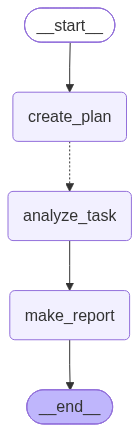

In [4]:
graph_builder = StateGraph(ReportState)

graph_builder.add_node("create_plan", create_plan)
graph_builder.add_node("analyze_task", analyze_task)
graph_builder.add_node("make_report", make_report)

graph_builder.add_edge(START, "create_plan")
# Orchestrator가 만든 작업 수만큼 동적 Fan-out
graph_builder.add_conditional_edges("create_plan", assign_workers, ["analyze_task"]) # ["analyze_task"] 는 {"analyze_task":"analyze_task"}라는 의미.
graph_builder.add_edge("analyze_task", "make_report")
graph_builder.add_edge("make_report", END)

send_graph = graph_builder.compile()
display(Image(send_graph.get_graph().draw_mermaid_png()))

### 동적 Fan-out과 Fan-in

`add_conditional_edges`는 `create_plan` 실행 후 `assign_workers`를 호출한다. 이 함수가 반환한 `Send` 수만큼 `analyze_task`가 동적으로 실행되는 과정이 **Fan-out**이다.

각 `analyze_task`에서 `make_report`로 이어지는 간선은 **Fan-in**을 만든다. LangGraph는 같은 단계에서 생성된 Worker들이 모두 완료될 때까지 기다린 뒤, reducer로 합쳐진 전체 `results`를 `make_report`에 전달한다. 따라서 Worker 하나가 끝날 때마다 보고서를 따로 만드는 것이 아니라 모든 분석 결과를 한 번에 종합한다.

아래 실행에서는 `stream_mode="updates"`를 사용한다. 노드가 State를 갱신할 때마다 `{노드 이름: 갱신 내용}` 형태의 값을 받아 Orchestrator의 계획, 각 Worker의 완료, 최종 보고서 생성을 순서대로 확인할 수 있다. Worker의 출력 순서는 매번 달라질 수 있으며, 이는 병렬 실행의 자연스러운 결과다.

In [5]:
request = "소규모 카페가 키오스크를 도입할 때 기대 효과와 위험을 분석해줘."

for chunk in send_graph.stream(
    {"request": request},
    stream_mode="updates",
):
    for node_name, update in chunk.items():
        if node_name == "create_plan":
            tasks = update["tasks"]
            print("\n" + "=" * 60)
            print(f"[Orchestrator] 분석 작업 {len(tasks)}개 생성")
            print("-" * 60)
            for task in tasks:
                print(f"• {task.title}")

        elif node_name == "analyze_task":
            item = update["results"][0]
            preview = " ".join(item["content"].split())[:150]
            print("\n" + "=" * 60)
            print(f"[Worker 완료] {item['title']}")
            print("-" * 60)
            print(f"{preview}...")

        elif node_name == "make_report":
            preview = " ".join(update["final_report"].split())[:500]
            print("\n" + "=" * 60)
            print("[최종 보고서]")
            print("-" * 60)
            print(f"{preview}...")
            print("=" * 60)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.



[Orchestrator] 분석 작업 4개 생성
------------------------------------------------------------
• 인력 효율화 및 운영 비용 절감 효과 분석
• 고객 경험 및 서비스 제공 측면의 영향 평가
• 초기 도입 비용 및 유지관리 위험 요인 분석
• 소규모 카페 맞춤형 도입 및 위험 완화 전략 수립
[analyze_task] '고객 경험 및 서비스 제공 측면의 영향 평가' 완료

[Worker 완료] 고객 경험 및 서비스 제공 측면의 영향 평가
------------------------------------------------------------
요청하신 전체 맥락(소규모 카페의 키오스크 도입)을 바탕으로, 담당 항목인 **‘고객 경험 및 서비스 제공 측면의 영향’**에 대해 구체적이고 다각적으로 분석한 보고서입니다. --- # [담당 항목 분석] 고객 경험 및 서비스 제공 측면의 영향 평가 소규모 카페에서 키...
[analyze_task] '초기 도입 비용 및 유지관리 위험 요인 분석' 완료

[Worker 완료] 초기 도입 비용 및 유지관리 위험 요인 분석
------------------------------------------------------------
제공해주신 요청사항과 담당 항목에 맞춰, **소규모 카페의 키오스크 도입 시 발생할 수 있는 '초기 도입 비용 및 유지관리 위험 요인'**을 구체적으로 분석한 보고서입니다. --- # [분석 보고서] 소규모 카페 키오스크 도입: 초기 비용 및 기술적 리스크 분석 ## ...
[analyze_task] '인력 효율화 및 운영 비용 절감 효과 분석' 완료

[Worker 완료] 인력 효율화 및 운영 비용 절감 효과 분석
------------------------------------------------------------
요청하신 전체 주제 중 **[인력 효율화 및 운영 비용 절감 효과 분석]** 담당 항목에 대해 소규모 카페의 특성

### Rate Limiting

**Rate Limit**은 LLM API Provider가 안정적인 서비스 운영과 과도한 사용 방지를 위해 일정 시간 동안의 요청량을 제한하는 정책이다. 제한 기준과 한도는 Provider, 모델, 사용 등급에 따라 다르며, 일반적으로 다음 항목을 사용한다.

- **RPM (Requests Per Minute)**: 분당 요청 수
- **TPM (Tokens Per Minute)**: 분당 처리 토큰 수
- **RPD (Requests Per Day)**: 일일 요청 수
- **동시 요청 수**: 같은 시점에 처리할 수 있는 요청 수

한도를 초과하면 일반적으로 `429 Too Many Requests` 또는 이에 대응하는 오류가 발생한다. Orchestrator가 작업 5개를 만들면 Worker의 LLM 요청도 짧은 시간에 최대 5개가 시작될 수 있으므로 순차 실행보다 Rate Limit에 걸리기 쉽다.

LangGraph의 `max_concurrency` 설정으로 한 번의 그래프 실행에서 동시에 수행할 수 있는 태스크 수를 제한할 수 있다. 전체 Worker 수를 줄이는 설정은 아니며, 실행 중인 Worker가 끝나면 대기하던 다음 Worker가 시작된다. 아래 예제는 8개 주제를 모두 분석하되 최대 3개 태스크만 동시에 실행한다.

`max_concurrency`는 순간적으로 요청이 몰리는 것을 완화하지만 RPM이나 TPM을 직접 계산하지는 않는다. 실제 Rate Limit에 대응하려면 재시도, exponential backoff, 요청 속도 제한 등을 함께 사용해야 한다. 특정 API 호출이나 코드 블록만 제한해야 하는 경우에는 `asyncio.Semaphore`를 사용할 수 있다.

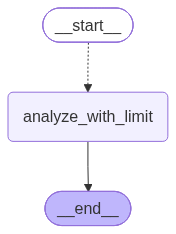

In [8]:
class RateLimitState(TypedDict):
    topics: list[str]
    results: Annotated[list, operator.add]


class RateLimitItemState(TypedDict):
    topic: str


def dispatch_topics(state: RateLimitState):
    return [
        Send("analyze_with_limit", {"topic": topic})
        for topic in state["topics"]
    ]


def analyze_with_limit(state: RateLimitItemState):
    topic = state["topic"]
    print(f"[시작] {topic} (현재 동시 실행 중)")
    result = llm.invoke(f"'{topic}'에 대해 한 문장으로 설명해줘.")
    print(f"[완료] {topic}")
    return {"results": [f"[{topic}] {result.text}"]}


graph_builder = StateGraph(RateLimitState)
graph_builder.add_node("analyze_with_limit", analyze_with_limit)

graph_builder.add_conditional_edges(START, dispatch_topics, ["analyze_with_limit"])
graph_builder.add_edge("analyze_with_limit", END)

rate_limit_graph = graph_builder.compile()
display(Image(rate_limit_graph.get_graph().draw_mermaid_png()))

In [9]:
topics = ["AI", "블록체인", "IoT", "클라우드", "5G", "메타버스", "드론", "AR/VR"]

result = rate_limit_graph.invoke(
    {"topics": topics},
    config={"max_concurrency": 3},
)

print(f"총 {len(topics)}개 주제, 동시 최대 3개 제한")
print(f"\n=== 결과 ===")
for r in result["results"]:
    print(r)

[시작] AI (현재 동시 실행 중)
[시작] 블록체인 (현재 동시 실행 중)
[시작] IoT (현재 동시 실행 중)
[완료] AI
[시작] 클라우드 (현재 동시 실행 중)
[완료] IoT
[시작] 5G (현재 동시 실행 중)
[완료] 블록체인
[시작] 메타버스 (현재 동시 실행 중)
[완료] 5G
[시작] 드론 (현재 동시 실행 중)
[완료] 클라우드
[시작] AR/VR (현재 동시 실행 중)
[완료] 메타버스
[완료] 드론
[완료] AR/VR
총 8개 주제, 동시 최대 3개 제한

=== 결과 ===
[AI] 인공지능(AI)은 인간의 학습, 추론, 판단 능력을 모방하여 컴퓨터가 스스로 생각하고 문제를 해결할 수 있도록 만드는 기술입니다.
[블록체인] 블록체인은 거래 정보를 담은 데이터 '블록'을 사슬처럼 연결하여 여러 컴퓨터에 분산 저장함으로써, 데이터의 위변조를 막는 투명하고 안전한 디지털 장부 기술입니다.
[IoT] **사물인터넷(IoT)**은 각종 사물에 센서와 통신 기능을 탑재해 인터넷으로 연결함으로써, 사람의 개입 없이 스스로 데이터를 수집하고 주고받으며 제어될 수 있게 하는 기술입니다.
[클라우드] 클라우드는 데이터를 자신의 기기에 직접 저장하지 않고, 인터넷을 통해 언제 어디서나 가상의 저장 공간과 IT 자원을 빌려 쓸 수 있는 서비스입니다.
[5G] 5G는 **초고속, 초저지연, 초연결**을 특징으로 하여 사람과 모든 사물을 실시간으로 연결하는 5세대 이동통신 기술입니다.
[메타버스] 메타버스는 가상현실(VR)과 증강현실(AR) 기술을 바탕으로 현실 세계와 연결되어, 사용자들이 아바타를 통해 사회·경제·문화적 활동을 할 수 있는 3차원 가상 공간입니다.
[드론] 드론은 조종사가 직접 탑승하지 않고 원격 조종이나 자율 주행을 통해 비행하는 무인 항공기입니다.
[AR/VR] **AR/VR은 현실 세계에 디지털 정보를 겹쳐 보여주거나(AR) 완전히 새로운 가상 공간을 구현하여(VR) 사용자에게 몰입형 경험을 제공하는 기술입니다.**


### 실습: 맞춤형 학습 자료 생성

사용자의 학습 요청을 바탕으로 맞춤형 학습 자료를 만드는 Orchestrator-worker 그래프를 완성하세요. 사용자는 목차를 직접 입력하지 않으며, Orchestrator가 학습 대상과 시간을 고려하여 필요한 목차를 동적으로 생성해야 합니다.

```
학습 요청 → 목차 생성 ─┬→ 목차별 Worker ─┐
                       ├→ 목차별 Worker ─┼→ 학습 자료 완성
                       └→ 목차별 Worker ─┘
```

요구사항:

- Orchestrator가 요청에 적합한 목차를 3~5개 생성한다.
- 생성된 목차마다 Worker를 동적으로 실행하여 설명과 간단한 예제를 작성한다.
- Worker의 결과를 모아 하나의 학습 자료로 완성하고 실행 과정을 출력한다.

구현할 때는 다음 요소를 확인하세요.

- 구조화 출력을 위한 목차 항목 모델과 목차 모델
- 전체 요청과 병합 결과를 저장할 그래프 State
- 목차 한 개만 전달받는 Worker State
- 학습 요청을 3~5개 목차로 나누는 Orchestrator 함수
- 목차마다 `Send`를 생성하는 라우팅 함수
- 설명과 예제를 작성하는 Worker 함수
- 병렬 결과를 순서대로 정리하여 학습 자료로 만드는 종합 함수
- `stream_mode="updates"`를 이용한 실행 과정 출력

병렬 Worker의 완료 순서는 보장되지 않는다. 최종 학습 자료의 목차 순서를 유지하려면 각 항목에 순번을 함께 전달하고 종합 단계에서 정렬한다.

In [24]:
class Section(BaseModel):
    title: str = Field(description="수업 자료 내용")
    description: str = Field(description="학습 목표")


class CoursePlan(BaseModel):
    sections: list[Section] = Field(description="수업자료의 제목, 학습 목표를 담은 리스트")


class CourseState(TypedDict):
    request: str
    sections: list[Section]
    results: Annotated[list, operator.add]
    final_result: str


class SectionState(TypedDict):
    request: str
    title: str 
    objective: str 
    order: int


def course_plan(state: CourseState):
    """필요한 수업 내용을 계획한다."""
    planner = llm.with_structured_output(CoursePlan)
    response = planner.invoke(
        f"다음 요청에 대한 수업 계획서를 작성하려고 한다. "
        f"요청에 맞는 학습 목차를 만들어줘. 목차에는 수업자료의 제목과 학습 목표를 포함해줘.\n\n요청: {state['request']}"
    )
    return {"sections": response.sections}

# 계획의 list를 worker에게 분배한다.
def assign_sections(state: CourseState):
    return [
        Send(
            "write_section",
            {
                "request": state["request"],
                "title": section.title,
                "objective": section.description,  # 핵심 수정
                "order": index,                    # task_id가 아니라 order
            },
        )
        for index, section in enumerate(state["sections"])
    ]


def write_section(state: WorkerState):
    result = llm.invoke(
        f"다음 <request>에 따른 학습자료를 만들어줘. 학습 제목은 <title> 학습 목표는 <objective>야. 마크다운 형식으로 깔끔하게 작성해줘.\n\n"
        """<request>
{state['request']}
<request>

<title>
{state['title']}
<title>

<objective>
{state['objective']}
<objective
"""
    )
    print(f"[analyze_task] '{state['title']}' 완료")

    # ReportState
    return {'results' : [{
                            'title' : state['title'],
                            'objective' : state['objective'],
                            'content' : result.text,
                            'order': state['order']
                        }]}


def merge_results(state : CourseState):
    results = state['results']
    results.sort(key=lambda x : x['order'])

    final_result = "\n\n".join([
        f"""
title : {result['title']} \n 
objective : {result['objective']}
content : {result['content']}
""" 
for result in results])

    return {'final_result' : final_result}

In [25]:
builder = StateGraph(CourseState)

builder.add_node('course_plan', course_plan)
builder.add_node('write_section', write_section)
builder.add_node('merge_results', merge_results)

builder.add_edge(START, 'course_plan')
builder.add_conditional_edges(
    'course_plan',
    assign_sections,
    ['write_section']
)
builder.add_edge('write_section', 'merge_results')
builder.add_edge('merge_results', END)

graph = builder.compile()

In [26]:
course_request = (
    "파이썬을 처음 배우는 비전공자를 위한 2시간 분량의 학습 자료를 만들어줘."
)

result = graph.invoke({'request' : course_request})

print(result)

[analyze_task] '4. 반복문(for)을 활용한 간단한 자동화 처리' 완료
[analyze_task] '3. 조건문(if)으로 상황에 따른 판단 구현하기' 완료
[analyze_task] '2. 변수와 기본 데이터 타입 이해하기' 완료
[analyze_task] '1. 파이썬과의 첫 만남과 출력문 작성하기' 완료
{'request': '파이썬을 처음 배우는 비전공자를 위한 2시간 분량의 학습 자료를 만들어줘.', 'sections': [Section(title='1. 파이썬과의 첫 만남과 출력문 작성하기', description='파이썬의 특징을 이해하고 print 함수를 사용해 원하는 메시지를 화면에 출력할 수 있습니다.'), Section(title='2. 변수와 기본 데이터 타입 이해하기', description='변수의 개념을 배우고 숫자, 문자열 등 다양한 형태의 데이터를 저장하고 활용하는 방법을 익힙니다.'), Section(title='3. 조건문(if)으로 상황에 따른 판단 구현하기', description='if 문을 사용하여 주어진 조건에 따라 프로그램이 서로 다른 동작을 수행하도록 제어할 수 있습니다.'), Section(title='4. 반복문(for)을 활용한 간단한 자동화 처리', description='for 문을 사용하여 반복적인 작업을 자동으로 빠르게 처리하는 프로그래밍 기초를 학습합니다.')], 'results': [{'title': '1. 파이썬과의 첫 만남과 출력문 작성하기', 'objective': '파이썬의 특징을 이해하고 print 함수를 사용해 원하는 메시지를 화면에 출력할 수 있습니다.', 'content': '요청하신 변수 값이 지정되지 않아, 대표적인 주제인 **[파이썬 기초: 변수와 자료형 이해하기]**를 예시로 하여 학습 자료를 작성하였습니다. \n\n필요에 따라 내용을 수정하여 사용하실 수 있도록 깔끔한 마크다운(Markdown) 형식으로 구성했습니다.\n\n---\n\n# 📘 [학습 자료] 파이

In [27]:
print(result['final_result'])


title : 1. 파이썬과의 첫 만남과 출력문 작성하기 
 
objective : 파이썬의 특징을 이해하고 print 함수를 사용해 원하는 메시지를 화면에 출력할 수 있습니다.
content : 요청하신 변수 값이 지정되지 않아, 대표적인 주제인 **[파이썬 기초: 변수와 자료형 이해하기]**를 예시로 하여 학습 자료를 작성하였습니다. 

필요에 따라 내용을 수정하여 사용하실 수 있도록 깔끔한 마크다운(Markdown) 형식으로 구성했습니다.

---

# 📘 [학습 자료] 파이썬 기초: 변수와 자료형

> **학습 안내**: 본 자료는 프로그래밍 입문자를 위해 파이썬의 가장 기본적인 개념인 **변수**와 **자료형**을 다룹니다.

---

## 🎯 학습 목표
1. **변수(Variable)**의 개념을 이해하고 올바르게 선언 및 할당할 수 있다.
2. 파이썬의 주요 **기본 자료형(숫자, 문자열, 불리언)**의 특징을 설명할 수 있다.
3. 자료형 간의 **형 변환(Casting)**을 이해하고 실제 코드에 적용할 수 있다.

---

## 📑 목차
1. [변수(Variable)의 개념](#1-변수variable의-개념)
2. [파이썬의 주요 기본 자료형](#2-파이썬의-주요-기본-자료형)
3. [자료형 확인 및 형 변환](#3-자료형-확인-및-형-변환)
4. [💡 실습 과제](#4--실습-과제)
5. [📌 핵심 요약](#5--핵심-요약)

---

## 1. 변수(Variable)의 개념

### 1.1 변수란 무엇인가요?
변수는 데이터를 담는 **'상자'** 또는 **'이름표가 붙은 메모리 공간'**입니다. 프로그램에서 다루는 숫자, 문자 등의 값을 저장해 두고 필요할 때마다 불러와 사용할 수 있습니다.

### 1.2 변수 선언 및 값 할당
파이썬에서는 변수 이름 오른쪽에 `=` (할당 연산자)를 사용하여 값을 저장합니다.

```python
# 변수 선언 및 할당
age = 25
name = "철수"
is_student = True

print(

In [28]:
for item in graph.stream({'request' : course_request}):
    for node_name, update in item.items():
        print('---------------------')
        print(node_name)
        print(update)


---------------------
course_plan
{'sections': [Section(title='1. 파이썬 시작하기 및 Hello World', description='파이썬의 특징을 이해하고 print 함수를 사용하여 화면에 원하는 메시지를 출력할 수 있다.'), Section(title='2. 변수와 기본 데이터 타입', description='변수의 개념을 이해하고 숫자, 문자열 등 기초 자료형을 선언하여 활용할 수 있다.'), Section(title='3. 조건문(if-else)으로 상황 판단하기', description='조건문을 사용해 주어진 조건에 따라 다르게 실행되는 프로그램을 작성할 수 있다.'), Section(title='4. 반복문(for)으로 반복 작업 자동화하기', description='반복문의 원리를 이해하고 반복적인 작업을 간단한 코드로 자동화할 수 있다.')]}
[analyze_task] '1. 파이썬 시작하기 및 Hello World' 완료
---------------------
write_section
{'results': [{'title': '1. 파이썬 시작하기 및 Hello World', 'objective': '파이썬의 특징을 이해하고 print 함수를 사용하여 화면에 원하는 메시지를 출력할 수 있다.', 'content': '제공해주신 요청 사항, 학습 제목, 학습 목표를 바탕으로 체계적이고 보기 쉽게 정리한 마크다운 학습 자료입니다. \n\n*(※ 만약 특정 주제에 대한 실제 데이터가 `{state}` 변수에 들어있다면, 아래의 구조와 스타일로 학습 자료가 생성됩니다. 이해를 돕기 위해 예시 내용을 채워 작성하였습니다.)*\n\n---\n\n# 📘 [학습 제목] {state[\'title\']}\n> **"데이터 분석의 첫걸음: Pandas DataFrame 완벽 가이드"**\n\n<br>\n\n## 🎯 학습 목표\n{state[\'objective\']}\n1. **Pandas의 핵심 객체인 

## 추가 실습

면접 문제 생성

입력 : 지원자의 직무 / 경력 등 필요한 정보들  
orchestrator : 평가 역량(llm이 판단)  
worker : 하나의 역량에 대한 질문 생성.


In [15]:
class Competency(BaseModel):
    name: str = Field(description="평가할 역량 이름")
    description: str = Field(description="이 역량에서 확인할 구체적 내용")


class InterviewPlan(BaseModel):
    competencies: list[Competency] = Field(description="지원자를 평가하는 데 필요한 역량 목록")

# 그래프 전체가 공유하는 공용저장소
class InterviewState(TypedDict):
    role: str
    experience: str
    candidate_info: str

    competencies: list[Competency]
    results: Annotated[list, operator.add]
    final_result: str

# Worker 한 명에게 전달하는 개별 지시서
class CompetencyState(TypedDict):
    role: str
    experience: str
    candidate_info: str

    competency_name: str
    competency_description: str
    order: int

# 섹션을 생성한다
def interview_plan(state: InterviewState):
    """필요한 지원 역량을 계획한다."""
    planner = llm.with_structured_output(InterviewPlan)
    response = planner.invoke(
        f"""다음 지원자를 면접하기 위해 평가해야 할 핵심 역량을 선정해줘.
역량은 3~5개로 구성하고, 각 역량에서 확인할 내용을 구체적으로 작성해줘.


<지원 직무>
{state['role']}
</지원 직무>

<경력>
{state['experience']}
</경력>

<지원자 정보>
{state['candidate_info']}
</지원자 정보>

"""
    )
    return {"competencies": response.competencies}

# 계획의 list를 worker에게 분배한다.
def assign_competency_workers(state: InterviewState):
    return [
        Send(
            "generate_questions",
            {
                "role": state["role"],
                "experience": state["experience"],
                "candidate_info": state["candidate_info"],
                "competency_name": competency.name,
                "competency_description": competency.description,
                "order": index,
            },
        )
        for index, competency in enumerate(state["competencies"])
    ]


def generate_questions(state: CompetencyState):
    response = llm.invoke(f"""
너는 전문 면접관이다.

다음 지원자의 '{state['competency_name']}' 역량을 평가할 수 있는
면접 질문을 3~5개 만들어줘.

질문은 지원자의 실제 경험과 판단 과정을 확인할 수 있도록 작성해줘.

<지원 직무>
{state['role']}
</지원 직무>

<경력>
{state['experience']}
</경력>

<지원자 정보>
{state['candidate_info']}
</지원자 정보>

<평가 역량>
{state['competency_name']}
</평가 역량>

<확인할 내용>
{state['competency_description']}
</확인할 내용>
""")

    return {
        "results": [{
            "order": state["order"],
            "competency": state["competency_name"],
            "description": state["competency_description"],
            "questions": response.text,
        }]
    }

def merge_questions(state: InterviewState):
    sorted_results = sorted(
        state["results"],
        key=lambda item: item["order"],
    )

    final_result = "\n\n".join(
        f"""## {item['competency']}

평가 내용: {item['description']}

{item['questions']}"""
        for item in sorted_results
    )

    return {
        "final_result": final_result
    }

In [16]:
builder = StateGraph(InterviewState)

builder.add_node("create_interview_plan", interview_plan)
builder.add_node("generate_questions", generate_questions)
builder.add_node("merge_questions", merge_questions)

builder.add_edge(START, "create_interview_plan")

builder.add_conditional_edges(
    "create_interview_plan",
    assign_competency_workers,
    ["generate_questions"],
)

builder.add_edge("generate_questions", "merge_questions")
builder.add_edge("merge_questions", END)

interview_graph = builder.compile()

In [17]:
result = interview_graph.invoke({
    "role": "백엔드 개발자",
    "experience": "3년",
    "candidate_info": "Python, FastAPI, PostgreSQL 프로젝트 경험",
    "results": [],
})

print(result["final_result"])

## Python 및 FastAPI 활용 능력

평가 내용: Python 비동기 처리(async/await)에 대한 이해와 FastAPI의 비동기 패러다임, Dependency Injection 시스템, Pydantic을 활용한 데이터 검증 및 API 구현 역량을 확인합니다.

안녕하세요. 3년 차 백엔드 개발자의 **'Python 및 FastAPI 활용 능력'**을 깊이 있게 평가할 수 있는 면접 질문 4가지를 제안합니다.

모든 질문은 단순 이론 확인을 넘어 **지원자의 실제 프로젝트 경험, 문제 해결 과정, 그리고 기술적 의사결정 이유**를 파악할 수 있도록 구성했습니다.

---

### 1. 비동기 처리(Async/Await) 및 이벤트 루프 이해도 평가
> **질문:**
> "FastAPI 프로젝트 진행 중 `async def`로 선언된 API 라우트 내부에서 **동기(Sync) 블로킹 코드**(예: 동기 DB 라이브러리, `requests` 모듈, 무거운 CPU 연산 등)로 인해 이벤트 루프가 멈추거나 성능이 저하되는 문제를 경험해보신 적이 있나요?
> 당시 문제를 어떻게 인지/진단하셨고, 이를 해결하기 위해 어떤 방식(예: 비동기 라이브러리 교체, `run_in_threadpool` 활용, 일반 `def` 함수로 변경 등)을 선택하셨는지 판단 이유와 함께 설명해 주세요."

* **평가 의도:** Python의 `asyncio` 동작 원리와 FastAPI의 스레드 풀 처리 방식을 정확히 이해하고 있는지, 성능 병목 현상을 해결한 실무 경험이 있는지 확인합니다.
* **꼬리 질문 포인트:** "만약 외부 API가 동기 SDK만 제공하는 상황이라면 FastAPI 내에서 이를 어떻게 안전하게 호출하시겠습니까?"

---

### 2. Dependency Injection (의존성 주입) 시스템 활용 능력 평가
> **질문:**
> "FastAPI의 `Depends`를 활용해 프로젝트의 의존성 주입 시스템을 구축해 본 경험을 들려주세요.
> 특히 **P